# MLP from scratch: Fashion-MNIST

Implement a NumPy MLP and study how network size, activation functions, regularization, normalization, and augmentation affect image classification.

In [ ]:
# Imports
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets, transforms


## Data preprocessing

In [ ]:
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True)

In [ ]:
X = train_dataset.data.numpy().astype(np.float32)
X = X.reshape(len(X), -1)

y = train_dataset.targets.numpy()

Shuffle the training data with seed 551, then split it into 48,000 training and 12,000 validation images.

In [ ]:
rng = np.random.default_rng(551)
indices = rng.permutation(len(X))

X = X[indices]
y = y[indices]

In [ ]:
X_train = X[:48000].copy()
X_val = X[48000:].copy()
y_train = y[:48000]
y_val = y[48000:]

Standardize pixels using a single mean and standard deviation calculated from the training split. Apply the same statistics to validation and test images.

In [ ]:
mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-8)
X_val = (X_val - mean) / (std + 1e-8)

T-shirt/top 4770
Trouser 4807
Pullover 4835
Dress 4833
Coat 4799
Sandal 4814
Shirt 4838
Sneaker 4714
Bag 4781
Ankle boot 4809


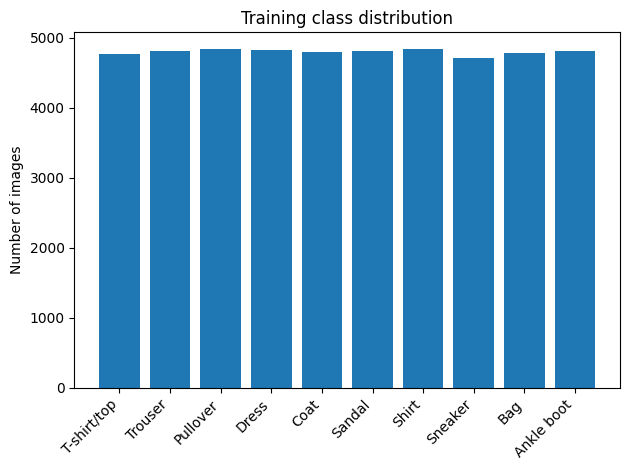

In [ ]:
classes, counts = np.unique(y_train, return_counts=True)

for label, count in zip(classes, counts):
    print(train_dataset.classes[label], count)

plt.bar(classes, counts)
plt.xticks(classes, train_dataset.classes, rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Training class distribution")
plt.tight_layout()
plt.show()

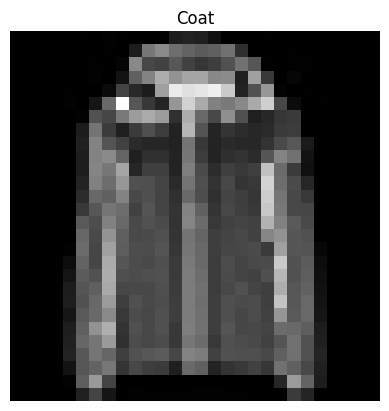

In [ ]:
i = np.random.randint(0, 48000)

image = train_dataset.data[i].numpy()
label = int(train_dataset.targets[i])

plt.imshow(image, cmap="gray")
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

In [ ]:
X

In [ ]:
X_test_unorm = test_dataset.data.numpy().astype(np.float32)
X_test_unorm = X_test_unorm.reshape(len(X_test_unorm), -1)

y_test = test_dataset.targets.numpy()

X_test = (X_test_unorm - mean) / (std + 1e-8)

## MLP implementation

In [ ]:
# Activation f'n and softmax for output layer
logistic = lambda z: 1./ (1 + np.exp(-z))
relu = lambda z: np.maximum(0, z)
leaky_relu = lambda z, g=0.01: np.maximum(g * z, z)
tanh = lambda z: np.tanh(z)

logistic_grad = lambda z: logistic(z) * (1 - logistic(z))
relu_grad = lambda z: (z > 0).astype(z.dtype)
leaky_relu_grad = lambda z, g=0.01: np.where(z > 0, 1.0, g).astype(z.dtype)
tanh_grad = lambda z: 1 - np.tanh(z)**2

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

### Accuracy

In [ ]:
def evaluate_acc(y, y_pred):
    return np.mean(y == y_pred)

### Model

In [ ]:
class MLP:

    def __init__(self, activation, activation_grad, hidden_layers=[64, 64], regularization=None, reg_strength=0.0):
        self.activation = activation
        self.activation_grad = activation_grad
        self.hidden_layers = hidden_layers
        self.regularization = regularization
        self.reg_strength = reg_strength

    def initialize_weights(self, input_dim, output_dim):
        layers = [input_dim] + self.hidden_layers + [output_dim]
        self.weights = []

        for i in range(len(layers) - 1):
            W = (
                np.random.randn(layers[i] + 1, layers[i + 1]) * 0.01
            ).astype(np.float32)
            self.weights.append(W)

    def fit(self, x, y, learning_rate, optimizer, batch_fn=None):
        N, D = x.shape

        def gradient(x, y, weights):
            N = x.shape[0]
            values = [x]
            preactivations = []

            for w in weights[:-1]:
                a = np.column_stack([values[-1], np.ones(N, dtype=x.dtype)])
                z = a @ w
                preactivations.append(z)
                values.append(self.activation(z))

            a = np.column_stack([values[-1], np.ones(N, dtype=x.dtype)])
            logits = a @ weights[-1]
            probabilities = softmax(logits)

            delta = probabilities.copy()
            delta[np.arange(N), y] -= 1
            delta /= N

            dweights = [None] * len(weights)

            for i in range(len(weights) - 1, -1, -1):
                a = np.column_stack([values[i], np.ones(N, dtype=x.dtype)])
                dweights[i] = a.T @ delta

                if self.regularization == "l1":
                    dweights[i][:-1] += (
                        self.reg_strength * np.sign(weights[i][:-1])
                    )
                elif self.regularization == "l2":
                    dweights[i][:-1] += (
                        self.reg_strength * weights[i][:-1]
                    )

                if i > 0:
                    delta = (delta @ weights[i][:-1].T) * self.activation_grad(
                        preactivations[i - 1]
                    )

            return dweights

        # Use the original small random initialization.
        input_dim = x.shape[1]
        output_dim = len(np.unique(y))
        self.initialize_weights(input_dim, output_dim)

        self.weights = optimizer.run(
            gradient, self.accuracy, x, y, self.weights, learning_rate,
            batch_fn=batch_fn,
        )
        return self

    def predict(self, x):
        N = x.shape[0]
        values = x

        for w in self.weights[:-1]:
            a = np.column_stack([values, np.ones(N, dtype=x.dtype)])
            z = a @ w
            values = self.activation(z)

        a = np.column_stack([values, np.ones(N, dtype=x.dtype)])
        logits = a @ self.weights[-1]
        probabilities = softmax(logits)

        return np.argmax(probabilities, axis=1)

    def accuracy(self, x, y):
        return evaluate_acc(y, self.predict(x))


### Mini-batch gradient descent

In [ ]:
class MiniBatchGradientDescent:

    def __init__(self, epochs=20, batch_size=128, record_by="epoch",
                 X_test=None, y_test=None):
        self.epochs = epochs
        self.batch_size = batch_size
        self.record_by = record_by
        self.X_test = X_test
        self.y_test = y_test

    def run(self, gradient_fn, accuracy_fn, x, y, weights,
            learning_rate=0.001, batch_fn=None):

        N = len(x)
        self.accuracy_history = []
        self.test_accuracy_history = []

        def record_history():
            self.accuracy_history.append(accuracy_fn(x, y))

            if self.X_test is not None:
                self.test_accuracy_history.append(
                    accuracy_fn(self.X_test, self.y_test)
                )

        record_history()

        for epoch in range(self.epochs):
            indices = np.random.permutation(N)

            for start in range(0, N, self.batch_size):
                batch = indices[start:start + self.batch_size]

                if batch_fn is None:
                    x_batch = x[batch]
                    y_batch = y[batch]
                else:
                    x_batch, y_batch = batch_fn(batch)

                grad = gradient_fn(x_batch, y_batch, weights)

                for i in range(len(weights)):
                    weights[i] -= learning_rate * grad[i]

            record_history()

        return weights

## Experiments

In [ ]:
def reset_seed(seed=551):
    np.random.seed(seed)
    torch.manual_seed(seed)

### Hyperparameter selection

Select the learning rate using a two-hidden-layer ReLU MLP with 256 units per hidden layer and batch size 128. Then compare batch sizes at learning rate 0.1.

In [ ]:
lrs = [.1, .01, .001, .0001]
batch_sizes = [128, 256, 512, 1024]
# Pair each activation with its derivative.
activation = [relu, leaky_relu, tanh, logistic]
activation_grad = [relu_grad, leaky_relu_grad, tanh_grad, logistic_grad]

for lr in lrs:
    np.random.seed(551) # reset seed for same random init
    optimizer = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
    model = MLP(relu, relu_grad, [256, 256])
    model.fit(X_train, y_train, lr, optimizer)
    print(evaluate_acc(y_val, model.predict(X_val)))

In [ ]:
# lr chosen is 0.1
for b in batch_sizes:
    reset_seed()

    optimizer = MiniBatchGradientDescent(
        epochs=20, batch_size=b, record_by=None
    )

    model = MLP(relu, relu_grad, [256, 256])
    model.fit(X_train, y_train, 0.1, optimizer)

    print(f"Batch size {b}: {evaluate_acc(y_val, model.predict(X_val)):.4f}")

The experiments below use batch size 128. Smaller batches were not evaluated because of training time. The saved learning-rate sweep was interrupted and does not provide a complete tuning record.

### Experiment 1: Network depth

In [ ]:
mlp_simple = MLP(relu, relu_grad, [])
mlp_one = MLP(relu, relu_grad, [256])
mlp_two = MLP(relu, relu_grad, [256, 256])

In [ ]:
reset_seed()

optimizer_simple = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_one = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_two = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_simple.fit(X_train, y_train, 0.1, optimizer_simple)
mlp_one.fit(X_train, y_train, 0.1, optimizer_one)
mlp_two.fit(X_train, y_train, 0.1, optimizer_two)

In [ ]:
plt.plot(optimizer_simple.accuracy_history, label="No hidden layers")
plt.plot(optimizer_one.accuracy_history, label="1 hidden layer")
plt.plot(optimizer_two.accuracy_history, label="2 hidden layers")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Network Depth on Training Accuracy")
plt.legend()

plt.xlim(0, 20)
plt.ylim(0.75, 1.0)
plt.xticks(range(2, 21, 2))
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("No hidden layers:", evaluate_acc(y_test, mlp_simple.predict(X_test)))
print("1 hidden layer:", evaluate_acc(y_test, mlp_one.predict(X_test)))
print("2 hidden layers:", evaluate_acc(y_test, mlp_two.predict(X_test)))

#### Experiment 1.1: Additional hidden layers

In [ ]:
reset_seed()

mlp_five = MLP(relu, relu_grad, [256, 256, 256, 256, 256])

optimizer_five = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_five.fit(X_train, y_train, 0.1, optimizer_five)

In [ ]:
plt.plot(optimizer_two.accuracy_history, label="2 hidden layers")
plt.plot(optimizer_five.accuracy_history, label="5 hidden layers")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Increasing Network Depth")
plt.legend()
plt.show()

print("5 hidden layers:", evaluate_acc(y_test, mlp_five.predict(X_test)))

In [ ]:
print("2 hidden layers (20 epochs):", evaluate_acc(y_test, mlp_two.predict(X_test)))
print("5 hidden layers (20 epochs):", evaluate_acc(y_test, mlp_five.predict(X_test)))

In [ ]:
reset_seed()

mlp_five = MLP(relu, relu_grad, [256, 256, 256, 256, 256])

optimizer_five = MiniBatchGradientDescent(epochs=30, batch_size=128, record_by="epoch")

mlp_five.fit(X_train, y_train, 0.1, optimizer_five)

In [ ]:
plt.plot(optimizer_two.accuracy_history, label="2 hidden layers")
plt.plot(optimizer_five.accuracy_history, label="5 hidden layers")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Increasing Network Depth")
plt.legend()
plt.show()

print("5 hidden layers:", evaluate_acc(y_test, mlp_five.predict(X_test)))

In [ ]:
print("5 hidden layers (30 epochs):", evaluate_acc(y_test, mlp_five.predict(X_test)))

#### Experiment 1.2: Hidden-layer width

In [ ]:
reset_seed()

mlp_64 = MLP(relu, relu_grad, [64, 64])
mlp_128 = MLP(relu, relu_grad, [128, 128])

optimizer_64 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_128 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_64.fit(X_train, y_train, 0.1, optimizer_64)
mlp_128.fit(X_train, y_train, 0.1, optimizer_128)

In [ ]:
plt.plot(optimizer_64.accuracy_history, label="64 units")
plt.plot(optimizer_128.accuracy_history, label="128 units")
plt.plot(optimizer_two.accuracy_history, label="256 units")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Network Width on Training Accuracy")
plt.legend()

plt.xlim(0, 20)
plt.ylim(0.75, 1.0)
plt.xticks(range(2, 21, 2))
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("Test accuracy:")
print("64 units:", evaluate_acc(y_test, mlp_64.predict(X_test)))
print("128 units:", evaluate_acc(y_test, mlp_128.predict(X_test)))
print("256 units:", evaluate_acc(y_test, mlp_two.predict(X_test)))

#### Experiment 1.3: Per-class accuracy

In [ ]:
pred_simple = mlp_simple.predict(X_test)
pred_one = mlp_one.predict(X_test)
pred_two = mlp_two.predict(X_test)

acc_simple = []
acc_one = []
acc_two = []

for c in range(10):
    mask = y_test == c

    acc_simple.append(evaluate_acc(y_test[mask], pred_simple[mask]))
    acc_one.append(evaluate_acc(y_test[mask], pred_one[mask]))
    acc_two.append(evaluate_acc(y_test[mask], pred_two[mask]))

In [ ]:
class_names = test_dataset.classes
positions = np.arange(10)

plt.figure(figsize=(12, 5))

plt.bar(positions - 0.25, acc_simple, width=0.25, label="0 hidden layers")
plt.bar(positions, acc_one, width=0.25, label="1 hidden layer")
plt.bar(positions + 0.25, acc_two, width=0.25, label="2 hidden layers")

plt.xticks(positions, class_names, rotation=45)
plt.xlabel("Clothing category")
plt.ylabel("Test accuracy")
plt.title("Effect of Network Depth on Per-Class Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

### Experiment 2: Activation functions

In [ ]:
reset_seed()

mlp_tanh = MLP(tanh, tanh_grad, [256, 256])
mlp_leaky_relu = MLP(leaky_relu, leaky_relu_grad, [256, 256])

In [ ]:
optimizer_t = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_l = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_tanh.fit(X_train, y_train, 0.1, optimizer_t)
mlp_leaky_relu.fit(X_train, y_train, 0.1, optimizer_l)

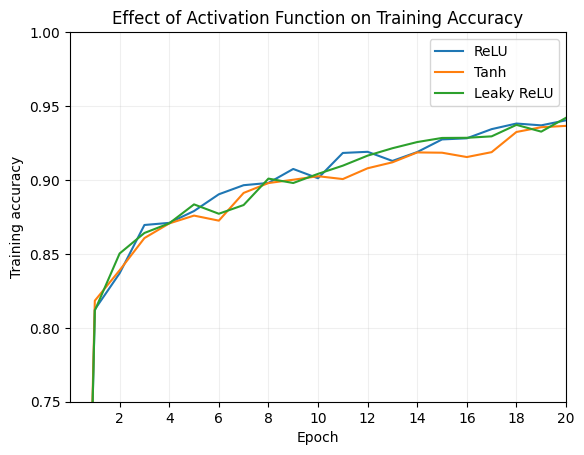

In [ ]:
plt.plot(optimizer_two.accuracy_history, label="ReLU")
plt.plot(optimizer_t.accuracy_history, label="Tanh")
plt.plot(optimizer_l.accuracy_history, label="Leaky ReLU")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Activation Function on Training Accuracy")
plt.legend()

plt.xlim(0, 20)
plt.ylim(0.75, 1.0)
plt.xticks(range(2, 21, 2))
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("ReLU:", evaluate_acc(y_test, mlp_two.predict(X_test)))
print("Tanh:", evaluate_acc(y_test, mlp_tanh.predict(X_test)))
print("Leaky ReLU:", evaluate_acc(y_test, mlp_leaky_relu.predict(X_test)))

ReLU: 0.8846
Tanh: 0.8829
Leaky ReLU: 0.8867


#### Experiment 2.1: Leaky ReLU slope

In [ ]:
reset_seed()

mlp_leaky_001 = MLP(
    lambda z: leaky_relu(z, g=0.001),
    lambda z: leaky_relu_grad(z, g=0.001),
    [256, 256]
)

mlp_leaky_1 = MLP(
    lambda z: leaky_relu(z, g=0.1),
    lambda z: leaky_relu_grad(z, g=0.1),
    [256, 256]
)

optimizer_leaky_001 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_leaky_1 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_leaky_001.fit(X_train, y_train, 0.1, optimizer_leaky_001)
mlp_leaky_1.fit(X_train, y_train, 0.1, optimizer_leaky_1)

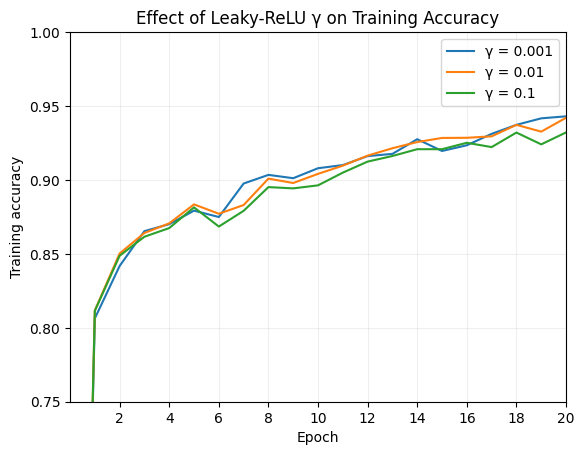

In [ ]:
plt.plot(optimizer_leaky_001.accuracy_history, label="γ = 0.001")
plt.plot(optimizer_l.accuracy_history, label="γ = 0.01")
plt.plot(optimizer_leaky_1.accuracy_history, label="γ = 0.1")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Leaky-ReLU γ on Training Accuracy")
plt.legend()

plt.xlim(0, 20)
plt.ylim(0.75, 1.0)
plt.xticks(range(2, 21, 2))
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("γ 0.001:", evaluate_acc(y_val, mlp_leaky_001.predict(X_val)))
print("γ 0.01:", evaluate_acc(y_val, mlp_leaky_relu.predict(X_val)))
print("γ 0.1:", evaluate_acc(y_val, mlp_leaky_1.predict(X_val)))

γ 0.001: 0.8941666666666667
γ 0.01: 0.89475
γ 0.1: 0.8930833333333333


### Experiment 3: L1 and L2 regularization

In [ ]:
reset_seed()

mlp_l1 = MLP(
    relu, relu_grad, [256, 256],
    regularization="l1", reg_strength=0.0001
)

mlp_l2 = MLP(
    relu, relu_grad, [256, 256],
    regularization="l2", reg_strength=0.0001
)

optimizer_l1 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_l2 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_l1.fit(X_train, y_train, 0.1, optimizer_l1)
mlp_l2.fit(X_train, y_train, 0.1, optimizer_l2)

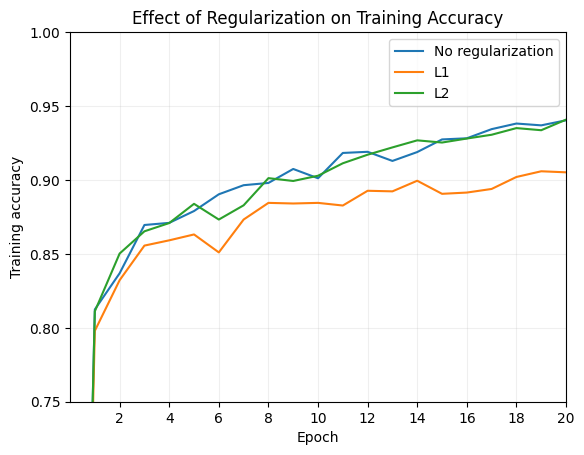

In [ ]:
plt.plot(optimizer_two.accuracy_history, label="No regularization")
plt.plot(optimizer_l1.accuracy_history, label="L1")
plt.plot(optimizer_l2.accuracy_history, label="L2")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Regularization on Training Accuracy")
plt.legend()

plt.xlim(0, 20)
plt.ylim(0.75, 1.0)
plt.xticks(range(2, 21, 2))
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("No regularization:", evaluate_acc(y_test, mlp_two.predict(X_test)))
print("L1:", evaluate_acc(y_test, mlp_l1.predict(X_test)))
print("L2:", evaluate_acc(y_test, mlp_l2.predict(X_test)))

No regularization: 0.8846
L1: 0.8733
L2: 0.8856


#### Experiment 3.1: Regularization strength

The saved L2 sweep was interrupted. Subsequent saved results are retained, but do not establish that the sweep completed in one run.

In [ ]:
reset_seed()

mlp_l1_weak = MLP(relu, relu_grad, [256, 256], regularization="l1", reg_strength=0.00001)
mlp_l1_strong = MLP(relu, relu_grad, [256, 256], regularization="l1", reg_strength=0.001)

optimizer_l1_weak = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_l1_strong = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_l1_weak.fit(X_train, y_train, 0.1, optimizer_l1_weak)
mlp_l1_strong.fit(X_train, y_train, 0.1, optimizer_l1_strong)

In [ ]:
reset_seed()

mlp_l2_weak = MLP(relu, relu_grad, [256, 256], regularization="l2", reg_strength=0.00001)
mlp_l2_strong = MLP(relu, relu_grad, [256, 256], regularization="l2", reg_strength=0.001)

optimizer_l2_weak = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_l2_strong = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_l2_weak.fit(X_train, y_train, 0.1, optimizer_l2_weak)
mlp_l2_strong.fit(X_train, y_train, 0.1, optimizer_l2_strong)

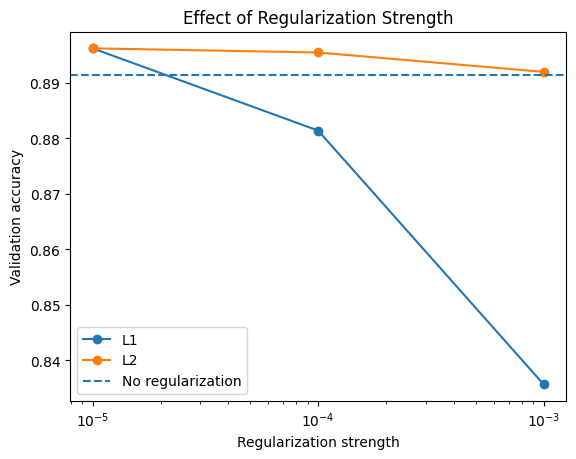

In [ ]:
reg_strengths = [0.00001, 0.0001, 0.001]

l1_val_acc = [
    evaluate_acc(y_val, mlp_l1_weak.predict(X_val)),
    evaluate_acc(y_val, mlp_l1.predict(X_val)),
    evaluate_acc(y_val, mlp_l1_strong.predict(X_val))
]

l2_val_acc = [
    evaluate_acc(y_val, mlp_l2_weak.predict(X_val)),
    evaluate_acc(y_val, mlp_l2.predict(X_val)),
    evaluate_acc(y_val, mlp_l2_strong.predict(X_val))
]

plt.plot(reg_strengths, l1_val_acc, marker="o", label="L1")
plt.plot(reg_strengths, l2_val_acc, marker="o", label="L2")

plt.axhline(mlp_two.accuracy(X_val, y_val), linestyle="--", label="No regularization")

plt.xscale("log")
plt.xlabel("Regularization strength")
plt.ylabel("Validation accuracy")
plt.title("Effect of Regularization Strength")
plt.legend()
plt.show()

In [ ]:
print("L1:")
print("0.00001:", l1_val_acc[0])
print("0.0001:", l1_val_acc[1])
print("0.001:", l1_val_acc[2])

print("\n")

print("L2:")
print("0.00001:", l2_val_acc[0])
print("0.0001:", l2_val_acc[1])
print("0.001:", l2_val_acc[2])

L1:
0.00001: 0.89625
0.0001: 0.8814166666666666
0.001: 0.8356666666666667


L2:
0.00001: 0.89625
0.0001: 0.8955
0.001: 0.892


In [ ]:
best_l1 = mlp_l1_weak
best_l2 = mlp_l2_weak

In [ ]:
print("No regularization:")
print("Training:", evaluate_acc(y_train, mlp_two.predict(X_train)))
print("Testing:", evaluate_acc(y_test, mlp_two.predict(X_test)))

print("\nL1:")
print("Training:", evaluate_acc(y_train, best_l1.predict(X_train)))
print("Testing:", evaluate_acc(y_test, best_l1.predict(X_test)))

print("\nL2:")
print("Training:", evaluate_acc(y_train, best_l2.predict(X_train)))
print("Testing:", evaluate_acc(y_test, best_l2.predict(X_test)))

No regularization:
Training: 0.9403541666666667
Testing: 0.8846

L1:
Training: 0.9397083333333334
Testing: 0.889

L2:
Training: 0.9447916666666667
Testing: 0.8897


### Experiment 4: Input normalization

The normalized and unnormalized models use learning rates 0.1 and 0.01, respectively, so this comparison does not isolate normalization alone.

In [ ]:
X_train_unorm = X[:48000].copy()
X_val_unorm = X[48000:].copy()

In [ ]:
reset_seed()

mlp_unorm = MLP(relu, relu_grad, [256, 256])
optimizer_unorm = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
mlp_unorm.fit(X_train_unorm, y_train, 0.01, optimizer_unorm)

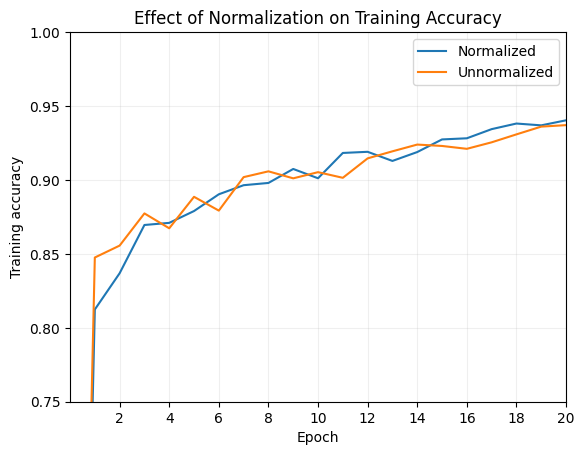

In [ ]:
plt.plot(optimizer_two.accuracy_history, label="Normalized")
plt.plot(optimizer_unorm.accuracy_history, label="Unnormalized")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Effect of Normalization on Training Accuracy")
plt.legend()

plt.xlim(0, 20)
plt.ylim(0.75, 1.0)
plt.xticks(range(2, 21, 2))
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("Normalized:", evaluate_acc(y_test, mlp_two.predict(X_test)))
print("Unnormalized:", evaluate_acc(y_test, mlp_unorm.predict(X_test_unorm)))

Normalized: 0.8846
Unnormalized: 0.8873


### Experiment 5: Data augmentation

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor()
])

aug_dataset = datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=train_transform
    )
train_indices = indices[:48000].copy()

In [ ]:
def augmented_batch(batch):
    images = []
    labels = []

    for position in batch:
        original_index = train_indices[position]
        image, label = aug_dataset[int(original_index)]

        image = image.numpy().reshape(-1) * 255.0
        image = (image - mean) / (std + 1e-8)

        images.append(image)
        labels.append(label)

    return (
        np.stack(images).astype(np.float32),
        np.asarray(labels, dtype=np.int64)
    )

In [ ]:
reset_seed()

mlp_aug = MLP(relu, relu_grad, [256, 256])
mlp_aug_l1 = MLP(relu, relu_grad, [256, 256], regularization="l1", reg_strength=0.00001)
mlp_aug_l2 = MLP(relu, relu_grad, [256, 256], regularization="l2", reg_strength=0.00001)

optimizer_aug = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_aug_l1 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")
optimizer_aug_l2 = MiniBatchGradientDescent(epochs=20, batch_size=128, record_by="epoch")

mlp_aug.fit(X_train, y_train, 0.1, optimizer_aug, batch_fn=augmented_batch)
mlp_aug_l1.fit(X_train, y_train, 0.1, optimizer_aug_l1, batch_fn=augmented_batch)
mlp_aug_l2.fit(X_train, y_train, 0.1, optimizer_aug_l2, batch_fn=augmented_batch)

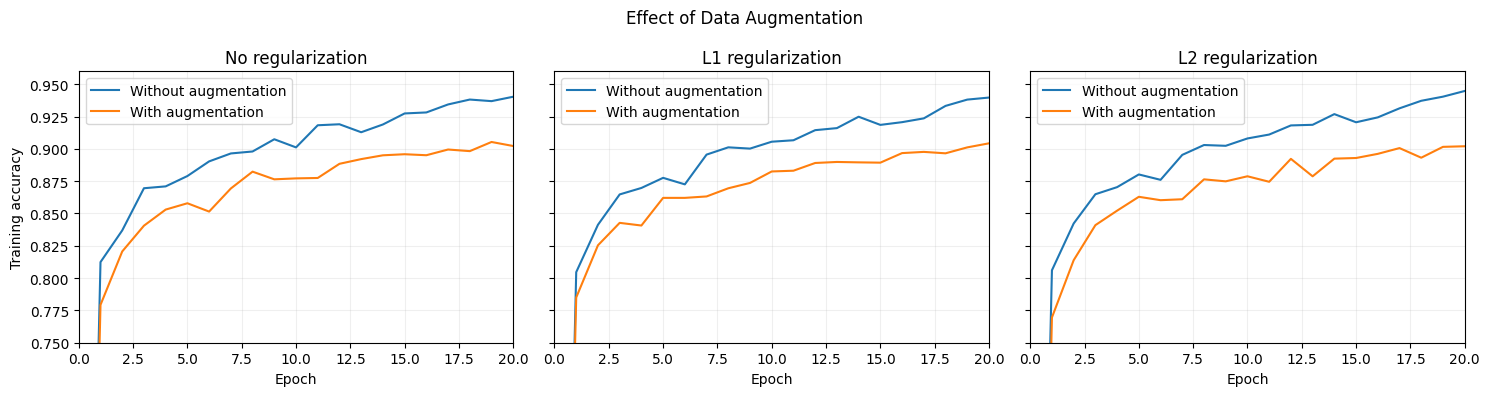

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# No regularization
axes[0].plot(optimizer_two.accuracy_history, label="Without augmentation")
axes[0].plot(optimizer_aug.accuracy_history, label="With augmentation")
axes[0].set_title("No regularization")

# L1 regularization
axes[1].plot(optimizer_l1_weak.accuracy_history, label="Without augmentation")
axes[1].plot(optimizer_aug_l1.accuracy_history, label="With augmentation")
axes[1].set_title("L1 regularization")

# L2 regularization
axes[2].plot(optimizer_l2_weak.accuracy_history, label="Without augmentation")
axes[2].plot(optimizer_aug_l2.accuracy_history, label="With augmentation")
axes[2].set_title("L2 regularization")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xlim(0, 20)
    ax.set_ylim(0.75, 0.96)
    ax.legend()
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Training accuracy")

fig.suptitle("Effect of Data Augmentation")
plt.tight_layout()
plt.show()

In [ ]:
print("No regularization:")
print("Without augmentation:", evaluate_acc(y_test, mlp_two.predict(X_test)))
print("With augmentation:", evaluate_acc(y_test, mlp_aug.predict(X_test)))

print("\n")

print("L1:")
print("Without augmentation:", evaluate_acc(y_test, best_l1.predict(X_test)))
print("With augmentation:", evaluate_acc(y_test, mlp_aug_l1.predict(X_test)))

print("\n")

print("L2:")
print("Without augmentation:", evaluate_acc(y_test, best_l2.predict(X_test)))
print("With augmentation:", evaluate_acc(y_test, mlp_aug_l2.predict(X_test)))

No regularization:
Without augmentation: 0.8846
With augmentation: 0.8725


L1:
Without augmentation: 0.889
With augmentation: 0.8782


L2:
Without augmentation: 0.8897
With augmentation: 0.8741


In [ ]:
reset_seed()
mlp_timed = MLP(relu, relu_grad, [256, 256], regularization="l1", reg_strength=0.00001)
mlp_timed.accuracy = lambda x, y: 0.0
optimizer_timed = MiniBatchGradientDescent(epochs=20, batch_size=128)

start = time.time()
mlp_timed.fit(X_train, y_train, 0.1, optimizer_timed, batch_fn=augmented_batch)
seconds = time.time() - start
print("training time:", round(seconds, 1), "seconds for 20 epochs (", round(seconds / 20, 2), "seconds per epoch )")

training time: 438.1 seconds for 20 epochs ( 21.9 seconds per epoch )


### Training duration: Accuracy over 100 epochs

In [ ]:
np.random.seed(551)

model = MLP(relu, relu_grad, [256, 256])

optimizer = MiniBatchGradientDescent(
    epochs=100,
    batch_size=128,
    X_test=X_test,
    y_test=y_test
)

model.fit(
    X_train, y_train, 0.1, optimizer
)

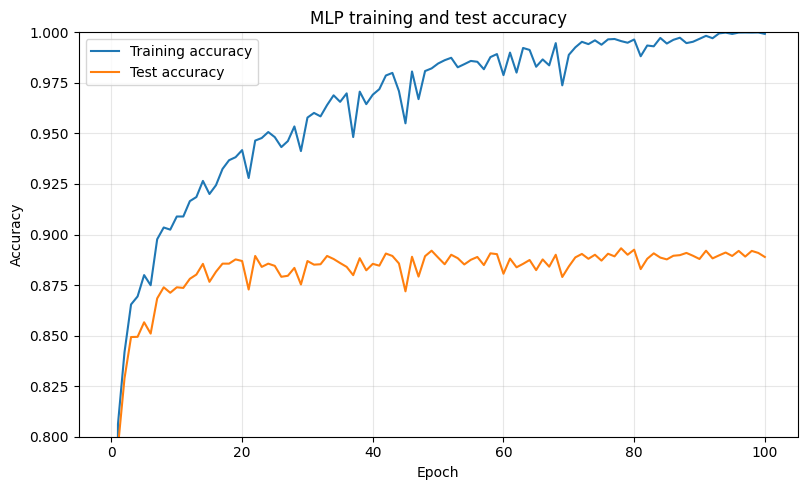

In [ ]:
epoch_numbers = np.arange(len(optimizer.accuracy_history))

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    optimizer.accuracy_history,
    label="Training accuracy"
)
plt.plot(
    epoch_numbers,
    optimizer.test_accuracy_history,
    label="Test accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP training and test accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.ylim(0.8, 1.0)
plt.show()

## Augmentation examples

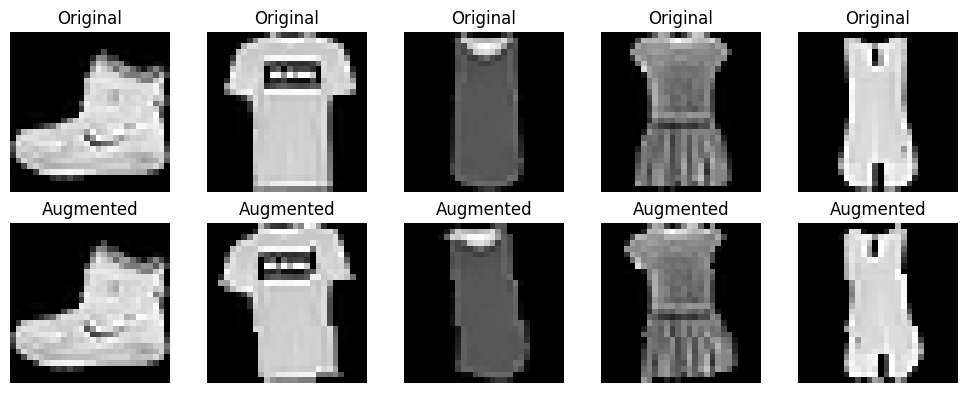

In [ ]:
reset_seed()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i in range(5):
    image, label = train_dataset[i]

    axes[0, i].imshow(image, cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(train_transform(image).squeeze(), cmap="gray")
    axes[1, i].set_title("Augmented")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()